# Sprawozdanie laboratoryjne

**Przedmiot:** Uczenie głębokie do rozpoznawania obiektów
**Zajęcia nr 2 / temat:** Trenowanie i strojenie klasyfikatora obrazów
**Autor / grupa:** Michał Pakuła / GL.03
**Data:** 21.10.2026

## 1. Cel ćwiczenia
Celem jest poprawa jakości i generalizacji klasyfikatora FashionMNIST z zajęć 1 (MLP). Wyznaczamy baseline (bez regularyzacji i augmentacji), badamy wpływ pięciu ulepszeń (augmentacja, BatchNorm, dropout, weight decay, scheduler LR), wybieramy konfigurację i checkpoint według **najniższej straty walidacyjnej** i porównujemy **lukę generalizacji** train–validation dla baseline i najlepszego wariantu. Zbiór testowy służy wyłącznie do końcowej oceny po zamrożeniu decyzji. Zakres dodatkowy: przegląd współczynnika uczenia i early stopping.

*Po chłopsku:* zbiór walidacyjny to „sprawdzian próbny", na którym wybieramy najlepszy model. Zbiór testowy to „egzamin właściwy", który otwieramy dopiero raz, na samym końcu, żeby wynik był uczciwy.

## 2. Metoda i implementacja
**Narzędzia:** Python, PyTorch, torchvision, pandas, matplotlib. Uruchamiane w Google Colab (GPU).

**Konfiguracja:**

| Element | Wartość |
|---|---|
| Zbiór | FashionMNIST, podział **50 000 trening / 10 000 walidacja / 10 000 test** |
| Podział | stałe indeksy (losowa permutacja, seed 42), te same dla wszystkich wariantów |
| Preprocessing | `ToTensor` + `Normalize(0.2860, 0.3530)` |
| Augmentacja (tylko trening) | `RandomHorizontalFlip` + `RandomCrop(28, padding=4)` |
| Model | `Flatten` → [`Linear` → (`BatchNorm1d`) → `ReLU` → (`Dropout`)] × 2 → `Linear(10)`, warstwy (256, 128) |
| Strata | Cross-Entropy |
| Optymalizator | Adam, lr = 1e-3 (wszystkie warianty) |
| Budżet | **20 epok** dla każdego wariantu, batch 128 |
| Scheduler | StepLR (co 6 epok, γ = 0,5), tylko tam, gdzie testowany |
| Weight decay | 1e-4 (Adam, kara L2), tylko tam, gdzie testowany |
| Dropout | p = 0,3, tylko tam, gdzie testowany |
| Seed | 0 (inicjalizacja i kolejność batchy) |

**Zasady eksperymentu:**
- **jeden czynnik naraz** względem baseline, potem kombinacje najlepszych,
- ten sam budżet epok i te same indeksy podziału dla wszystkich wariantów,
- augmentacja tylko na zbiorze treningowym; wszystkie straty „czystej oceny" (train_eval, val, test) liczone w trybie `eval()` na danych **bez** augmentacji,
- **wybór modelu po stracie walidacyjnej** (checkpoint z epoki z najmniejszym `val_loss`); zbiór testowy nie jest używany do żadnych decyzji.

In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import transforms

SEED = 0
EPOCHS = 20
BATCH = 128
NUM_WORKERS = 2
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu130 | urządzenie: cuda


### 2.1 Dane i stały podział train / val / test
Zbiór treningowy (60 000) dzielimy **raz** na 50 000 / 10 000 losową permutacją z ustalonym seedem. Indeksy są wspólne dla wszystkich wariantów. Ten sam zbiór wczytujemy w dwóch wersjach transformacji (czysta i z augmentacją), ale z **tymi samymi indeksami**.

In [2]:
mean, std = 0.2860, 0.3530

test_tf = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((mean,), (std,))]
)
aug_tf = transforms.Compose(
    [
        transforms.RandomHorizontalFlip(),
        transforms.RandomCrop(28, padding=4),
        transforms.ToTensor(),
        transforms.Normalize((mean,), (std,)),
    ]
)

ds_plain = torchvision.datasets.FashionMNIST(
    "./data", train=True, download=True, transform=test_tf
)
ds_aug = torchvision.datasets.FashionMNIST(
    "./data", train=True, download=True, transform=aug_tf
)
test_ds = torchvision.datasets.FashionMNIST(
    "./data", train=False, download=True, transform=test_tf
)
classes = test_ds.classes

# stały podział 50 000 / 10 000 (te same indeksy dla wszystkich wariantów)
split_gen = torch.Generator().manual_seed(42)
perm = torch.randperm(len(ds_plain), generator=split_gen).tolist()
train_idx, val_idx = perm[:50_000], perm[50_000:]
assert set(train_idx).isdisjoint(val_idx)
print(
    f"Trening: {len(train_idx)} | walidacja: {len(val_idx)} | "
    f"test: {len(test_ds)}"
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 211kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.95MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.0MB/s]

Trening: 50000 | walidacja: 10000 | test: 10000


In [3]:
def make_loader(ds, idx, shuffle, batch_size, seed=SEED):
    gen = torch.Generator().manual_seed(seed)
    return DataLoader(
        Subset(ds, idx),
        batch_size=batch_size,
        shuffle=shuffle,
        generator=gen if shuffle else None,
        num_workers=NUM_WORKERS,
        persistent_workers=NUM_WORKERS > 0,
    )


# ewaluacja zawsze na danych BEZ augmentacji (ds_plain / test_ds)
train_eval_loader = make_loader(ds_plain, train_idx, False, 1000)
val_loader = make_loader(ds_plain, val_idx, False, 1000)
test_loader = DataLoader(test_ds, batch_size=1000, shuffle=False)

### 2.2 Model, ewaluacja i funkcja treningu
`MLP` ma przełączniki BatchNorm i dropout. `run_experiment` trenuje model przez stały budżet epok i **po każdej epoce** liczy w trybie `eval()`: stratę i accuracy na treningu (czysta ocena), stratę i accuracy na walidacji. Zapamiętuje checkpoint z najniższą stratą walidacyjną (opcjonalnie z early stoppingiem). Zbiór testowy nie jest tu w ogóle używany.

In [4]:
class MLP(nn.Module):
    def __init__(
        self,
        in_dim=28 * 28,
        hidden=(256, 128),
        n_classes=10,
        use_bn=False,
        p_drop=0.0,
    ):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    crit = nn.CrossEntropyLoss(reduction="sum")
    loss_sum, correct, total = 0.0, 0, 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss_sum += crit(out, yb).item()
        correct += (out.argmax(1) == yb).sum().item()
        total += yb.numel()
    return loss_sum / total, correct / total

In [5]:
def run_experiment(
    name,
    epochs=EPOCHS,
    lr=1e-3,
    augment=False,
    use_bn=False,
    p_drop=0.0,
    weight_decay=0.0,
    optimizer="adam",
    use_scheduler=False,
    sched_step=None,
    patience=None,
    seed=SEED,
    verbose=False,
):
    kwargs = dict(
        epochs=epochs,
        lr=lr,
        augment=augment,
        use_bn=use_bn,
        p_drop=p_drop,
        weight_decay=weight_decay,
        optimizer=optimizer,
        use_scheduler=use_scheduler,
        sched_step=sched_step,
    )
    torch.manual_seed(seed)  # ta sama inicjalizacja wag
    model_cfg = dict(use_bn=use_bn, p_drop=p_drop)
    model = MLP(**model_cfg).to(device)
    train_loader = make_loader(
        ds_aug if augment else ds_plain, train_idx, True, BATCH, seed
    )
    criterion = nn.CrossEntropyLoss()
    if optimizer == "adam":
        opt = torch.optim.Adam(
            model.parameters(), lr=lr, weight_decay=weight_decay
        )
    elif optimizer == "sgd":
        opt = torch.optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=0.9,
            weight_decay=weight_decay,
        )
    else:
        raise ValueError(f"nieznany optymalizator: {optimizer}")
    sched = None
    if use_scheduler:
        step = sched_step or max(1, epochs // 3)
        sched = torch.optim.lr_scheduler.StepLR(opt, step_size=step, gamma=0.5)

    keys = [
        "train_loss",
        "train_eval_loss",
        "train_eval_acc",
        "val_loss",
        "val_acc",
    ]
    hist = {k: [] for k in keys}
    best_val, best_epoch, best_state, wait = float("inf"), 0, None, 0

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            running += loss.item() * yb.numel()
        if sched is not None:
            sched.step()

        tr_eval_loss, tr_eval_acc = evaluate(model, train_eval_loader)
        val_loss, val_acc = evaluate(model, val_loader)
        hist["train_loss"].append(running / len(train_idx))
        hist["train_eval_loss"].append(tr_eval_loss)
        hist["train_eval_acc"].append(tr_eval_acc)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)

        if val_loss < best_val:  # checkpoint po najniższej stracie walidacji
            best_val, best_epoch, wait = val_loss, epoch, 0
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
        else:
            wait += 1

        if verbose:
            print(
                f"Epoka {epoch:2d} | trening {hist['train_loss'][-1]:.3f} | "
                f"train_eval {tr_eval_loss:.3f} | val {val_loss:.3f} | "
                f"val acc {val_acc * 100:.2f}%"
            )
        if patience is not None and wait >= patience:
            print(f"Early stopping po epoce {epoch} (najlepsza: {best_epoch})")
            break

    return dict(
        name=name,
        kwargs=kwargs,
        model_cfg=model_cfg,
        hist=hist,
        best_epoch=best_epoch,
        best_state=best_state,
        params=count_params(model),
    )


def summarize(res):
    h, i = res["hist"], res["best_epoch"] - 1
    return {
        "konfiguracja": res["name"],
        "wybrana epoka": res["best_epoch"],
        "val accuracy [%]": round(h["val_acc"][i] * 100, 2),
        "val loss": round(h["val_loss"][i], 3),
        "train_eval loss": round(h["train_eval_loss"][i], 3),
        "luka (val − train_eval)": round(
            h["val_loss"][i] - h["train_eval_loss"][i], 3
        ),
        "train_eval acc [%]": round(h["train_eval_acc"][i] * 100, 2),
    }


def plot_curves(res, title):
    h = res["hist"]
    ep = range(1, len(h["val_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(ep, h["train_loss"], "--", label="trening (w trakcie epoki)")
    ax1.plot(ep, h["train_eval_loss"], ":", label="trening (czysta ocena)")
    ax1.plot(ep, h["val_loss"], "-", label="walidacja")
    ax1.axvline(res["best_epoch"], color="gray", ls="--", lw=0.8)
    ax1.set_xlabel("epoka")
    ax1.set_ylabel("strata (CE)")
    ax1.set_title(f"Krzywe straty: {title}")
    ax1.legend(fontsize=8)
    ax2.plot(
        ep,
        [a * 100 for a in h["train_eval_acc"]],
        ":",
        label="trening (czysta ocena)",
    )
    ax2.plot(ep, [a * 100 for a in h["val_acc"]], "-", label="walidacja")
    ax2.axvline(res["best_epoch"], color="gray", ls="--", lw=0.8)
    ax2.set_xlabel("epoka")
    ax2.set_ylabel("accuracy [%]")
    ax2.set_title("Accuracy")
    ax2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 3. Wyniki

### 3.1 Baseline
Baseline = model z zajęć 1: MLP (256, 128), Adam lr = 1e-3, **bez** regularyzacji i **bez** augmentacji, 20 epok. Wynik oceniamy na zbiorze walidacyjnym.

Epoka  1 | trening 0.505 | train_eval 0.408 | val 0.430 | val acc 83.79%
Epoka  2 | trening 0.357 | train_eval 0.333 | val 0.375 | val acc 86.14%
Epoka  3 | trening 0.320 | train_eval 0.280 | val 0.331 | val acc 87.95%
Epoka  4 | trening 0.295 | train_eval 0.259 | val 0.317 | val acc 88.40%
Epoka  5 | trening 0.273 | train_eval 0.242 | val 0.311 | val acc 88.56%
Epoka  6 | trening 0.255 | train_eval 0.245 | val 0.323 | val acc 88.08%
Epoka  7 | trening 0.237 | train_eval 0.225 | val 0.310 | val acc 89.09%
Epoka  8 | trening 0.227 | train_eval 0.208 | val 0.318 | val acc 88.91%
Epoka  9 | trening 0.216 | train_eval 0.190 | val 0.304 | val acc 88.86%
Epoka 10 | trening 0.201 | train_eval 0.183 | val 0.325 | val acc 88.67%
Epoka 11 | trening 0.192 | train_eval 0.173 | val 0.318 | val acc 89.35%
Epoka 12 | trening 0.182 | train_eval 0.171 | val 0.335 | val acc 88.90%
Epoka 13 | trening 0.174 | train_eval 0.166 | val 0.348 | val acc 89.02%
Epoka 14 | trening 0.167 | train_eval 0.162 | val 0

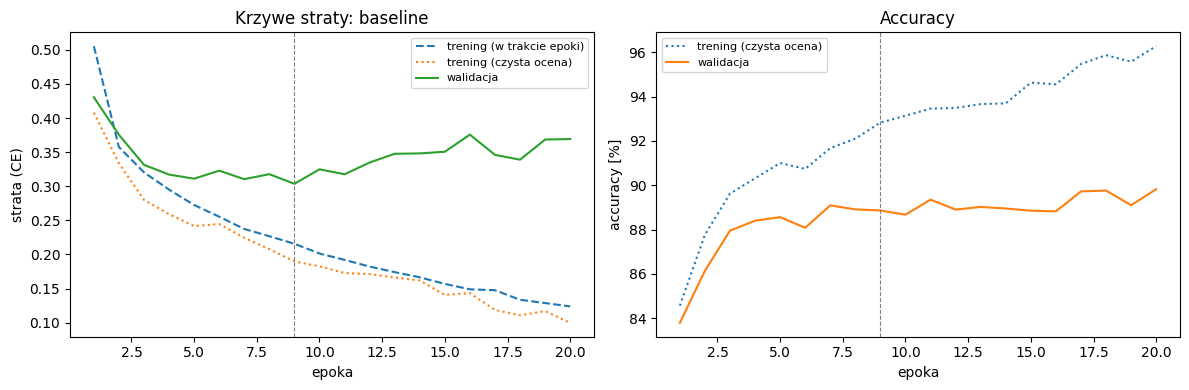

In [6]:
results = {}
results["baseline"] = run_experiment("baseline", verbose=True)
print(pd.DataFrame([summarize(results["baseline"])]).T)
plot_curves(results["baseline"], "baseline")

### 3.2 Pojedyncze ulepszenia (jeden czynnik naraz)
Każde ulepszenie włączamy **osobno**, względem baseline, z tym samym budżetem 20 epok.

In [7]:
single = [
    ("+ augmentacja", dict(augment=True)),
    ("+ BatchNorm", dict(use_bn=True)),
    ("+ dropout 0.3", dict(p_drop=0.3)),
    ("+ weight decay 1e-4", dict(weight_decay=1e-4)),
    ("+ scheduler StepLR", dict(use_scheduler=True)),
]
for name, kw in single:
    results[name] = run_experiment(name, **kw)
    s = summarize(results[name])
    gap = s["luka (val − train_eval)"]
    print(
        f"{name:22s} | epoka {s['wybrana epoka']:2d} | "
        f"val acc {s['val accuracy [%]']:.2f}% | luka {gap:.3f}"
    )

+ augmentacja          | epoka 19 | val acc 85.26% | luka 0.022
+ BatchNorm            | epoka 10 | val acc 89.73% | luka 0.166
+ dropout 0.3          | epoka 14 | val acc 89.30% | luka 0.097
+ weight decay 1e-4    | epoka 11 | val acc 89.69% | luka 0.122
+ scheduler StepLR     | epoka  7 | val acc 89.41% | luka 0.092


### 3.3 Kombinacje ulepszeń
Po zbadaniu pojedynczych czynników sprawdzamy kilka kombinacji (nadal ten sam budżet 20 epok).

In [8]:
combos = [
    ("BN + dropout", dict(use_bn=True, p_drop=0.3)),
    ("aug + BN + dropout", dict(augment=True, use_bn=True, p_drop=0.3)),
    (
        "wszystko razem",
        dict(
            augment=True,
            use_bn=True,
            p_drop=0.3,
            weight_decay=1e-4,
            use_scheduler=True,
        ),
    ),
]
for name, kw in combos:
    results[name] = run_experiment(name, **kw)
    s = summarize(results[name])
    gap = s["luka (val − train_eval)"]
    print(
        f"{name:22s} | epoka {s['wybrana epoka']:2d} | "
        f"val acc {s['val accuracy [%]']:.2f}% | luka {gap:.3f}"
    )

BN + dropout           | epoka 14 | val acc 89.93% | luka 0.104
aug + BN + dropout     | epoka 19 | val acc 84.35% | luka 0.013
wszystko razem         | epoka 20 | val acc 83.52% | luka 0.016


### 3.4 Tabela wyników i wybór konfiguracji
Konfigurację i checkpoint wybieramy według **najniższej straty walidacyjnej** (`val loss`). Luka generalizacji = `val_loss − train_eval_loss` w wybranej epoce (obie straty w trybie `eval()`, bez augmentacji).

In [9]:
df = pd.DataFrame([summarize(r) for r in results.values()])
df = df.sort_values("val loss").reset_index(drop=True)
display(df)
print(df.to_markdown(index=False))  # do wklejenia w sprawozdaniu

best_name = min(results, key=lambda k: min(results[k]["hist"]["val_loss"]))
print("\nWybrana konfiguracja (najniższa strata walidacyjna):", best_name)

,konfiguracja,wybrana epoka,val accuracy [%],val loss,train_eval loss,luka (val − train_eval),train_eval acc [%]
0,BN + dropout,14,89.93,0.281,0.176,0.104,93.59
1,+ scheduler StepLR,7,89.41,0.290,0.198,0.092,92.69
2,+ dropout 0.3,14,89.30,0.300,0.202,0.097,92.37
3,+ BatchNorm,10,89.73,0.302,0.136,0.166,95.10
4,+ weight decay 1e-4,11,89.69,0.304,0.183,0.122,93.19
5,baseline,9,88.86,0.304,0.190,0.114,92.82
6,+ augmentacja,19,85.26,0.406,0.383,0.022,85.75
7,aug + BN + dropout,19,84.35,0.437,0.424,0.013,84.45
8,wszystko razem,20,83.52,0.437,0.422,0.016,84.31


| konfiguracja        |   wybrana epoka |   val accuracy [%] |   val loss |   train_eval loss |   luka (val − train_eval) |   train_eval acc [%] |
|:--------------------|----------------:|-------------------:|-----------:|------------------:|--------------------------:|---------------------:|
| BN + dropout        |              14 |              89.93 |      0.281 |             0.176 |                     0.104 |                93.59 |
| + scheduler StepLR  |               7 |              89.41 |      0.29  |             0.198 |                     0.092 |                92.69 |
| + dropout 0.3       |              14 |              89.3  |      0.3   |             0.202 |                     0.097 |                92.37 |
| + BatchNorm         |              10 |              89.73 |      0.302 |             0.136 |                     0.166 |                95.1  |
| + weight decay 1e-4 |              11 |              89.69 |      0.304 |             0.183 |                     0.

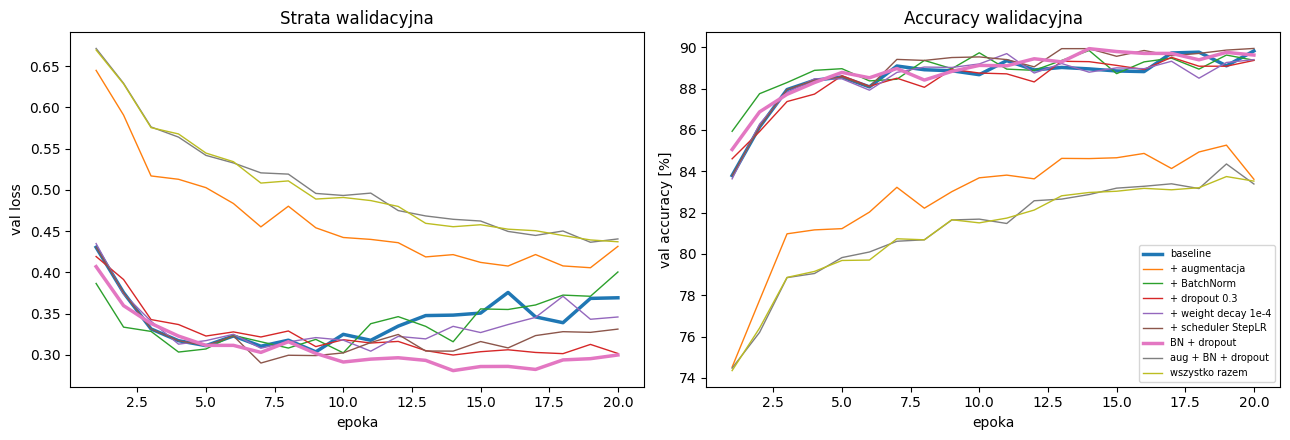

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, r in results.items():
    ep = range(1, len(r["hist"]["val_loss"]) + 1)
    bold = name in ("baseline", best_name)
    ax1.plot(ep, r["hist"]["val_loss"], label=name, lw=2.5 if bold else 1)
    ax2.plot(
        ep,
        [a * 100 for a in r["hist"]["val_acc"]],
        label=name,
        lw=2.5 if bold else 1,
    )
ax1.set_xlabel("epoka")
ax1.set_ylabel("val loss")
ax1.set_title("Strata walidacyjna")
ax2.set_xlabel("epoka")
ax2.set_ylabel("val accuracy [%]")
ax2.set_title("Accuracy walidacyjna")
ax2.legend(fontsize=7)
plt.tight_layout()
plt.show()

### 3.5 Krzywe uczenia wybranego modelu

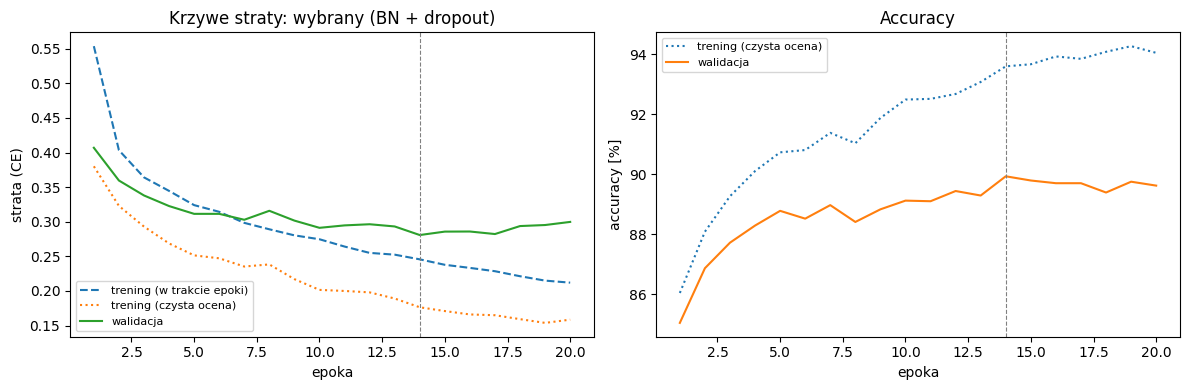

In [11]:
plot_curves(results[best_name], f"wybrany ({best_name})")

### 3.6 Luka generalizacji: baseline vs najlepszy wariant
Luka = `val_loss − train_eval_loss` w wybranej epoce. Komentując, patrz razem z accuracy: **mała luka przy słabym wyniku może oznaczać niedouczenie**, a nie dobrą generalizację.

In [12]:
gap_names = list(dict.fromkeys(["baseline", best_name]))
gap_df = pd.DataFrame([summarize(results[n]) for n in gap_names])
display(gap_df)
print(gap_df.to_markdown(index=False))

,konfiguracja,wybrana epoka,val accuracy [%],val loss,train_eval loss,luka (val − train_eval),train_eval acc [%]
0,baseline,9,88.86,0.304,0.190,0.114,92.82
1,BN + dropout,14,89.93,0.281,0.176,0.104,93.59


| konfiguracja   |   wybrana epoka |   val accuracy [%] |   val loss |   train_eval loss |   luka (val − train_eval) |   train_eval acc [%] |
|:---------------|----------------:|-------------------:|-----------:|------------------:|--------------------------:|---------------------:|
| baseline       |               9 |              88.86 |      0.304 |             0.19  |                     0.114 |                92.82 |
| BN + dropout   |              14 |              89.93 |      0.281 |             0.176 |                     0.104 |                93.59 |


### 3.7 Końcowa ocena na zbiorze testowym (decyzja zamrożona)
**Uwaga:** poniższa komórka to jedyne miejsce, w którym używamy zbioru testowego. Uruchamiamy ją **po** wyborze konfiguracji i checkpointu na podstawie walidacji. Wyniku nie wolno używać do dalszego strojenia.

In [13]:
final_rows = []
for name in gap_names:
    r = results[name]
    model = MLP(**r["model_cfg"]).to(device)
    model.load_state_dict(r["best_state"])
    test_loss, test_acc = evaluate(model, test_loader)
    i = r["best_epoch"] - 1
    final_rows.append(
        {
            "model": name,
            "wybrana epoka": r["best_epoch"],
            "val accuracy [%]": round(r["hist"]["val_acc"][i] * 100, 2),
            "test accuracy [%]": round(test_acc * 100, 2),
            "test loss": round(test_loss, 3),
        }
    )
final_df = pd.DataFrame(final_rows)
display(final_df)
print(final_df.to_markdown(index=False))

,model,wybrana epoka,val accuracy [%],test accuracy [%],test loss
0,baseline,9,88.86,88.37,0.329
1,BN + dropout,14,89.93,89.52,0.300


| model        |   wybrana epoka |   val accuracy [%] |   test accuracy [%] |   test loss |
|:-------------|----------------:|-------------------:|--------------------:|------------:|
| baseline     |               9 |              88.86 |               88.37 |       0.329 |
| BN + dropout |              14 |              89.93 |               89.52 |       0.3   |


### 3.8 Zakres dodatkowy: przegląd współczynnika uczenia
Baseline (bez regularyzacji), 10 epok, różne LR; oceniamy na **walidacji** (nie na teście). Jest to eksploracja niezależna od głównego porównania, w którym LR = 1e-3 dla wszystkich wariantów.

,lr,wybrana epoka,val accuracy [%],val loss
0,0.1000,7,10.27,2.304
1,0.0100,4,86.47,0.388
2,0.0010,9,88.86,0.304
3,0.0001,10,87.39,0.350


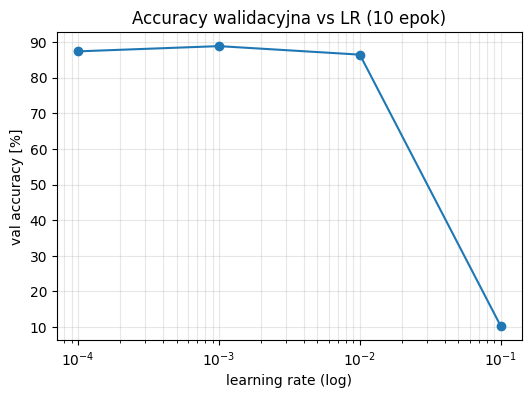

In [14]:
lrs = [1e-1, 1e-2, 1e-3, 1e-4]
lr_rows = []
for lr in lrs:
    r = run_experiment(f"lr={lr}", epochs=10, lr=lr)
    i = r["best_epoch"] - 1
    lr_rows.append(
        {
            "lr": lr,
            "wybrana epoka": r["best_epoch"],
            "val accuracy [%]": round(r["hist"]["val_acc"][i] * 100, 2),
            "val loss": round(r["hist"]["val_loss"][i], 3),
        }
    )
lr_df = pd.DataFrame(lr_rows)
display(lr_df)

plt.figure(figsize=(6, 4))
plt.semilogx(lr_df["lr"], lr_df["val accuracy [%]"], "o-")
plt.xlabel("learning rate (log)")
plt.ylabel("val accuracy [%]")
plt.title("Accuracy walidacyjna vs LR (10 epok)")
plt.grid(True, which="both", alpha=0.3)
plt.show()

### 3.9 Zakres dodatkowy: early stopping
Najlepsza konfiguracja, do 60 epok, zatrzymanie po 5 epokach bez poprawy straty walidacyjnej z przywróceniem najlepszego checkpointu (przechowywanego w `best_state`). Harmonogram LR zachowuje ten sam krok co w głównym eksperymencie (`sched_step`).

Early stopping po epoce 19 (najlepsza: 14)
                                                     0
konfiguracja             BN + dropout + early stopping
wybrana epoka                                       14
val accuracy [%]                                 89.93
val loss                                         0.281
train_eval loss                                  0.176
luka (val − train_eval)                          0.104
train_eval acc [%]                               93.59


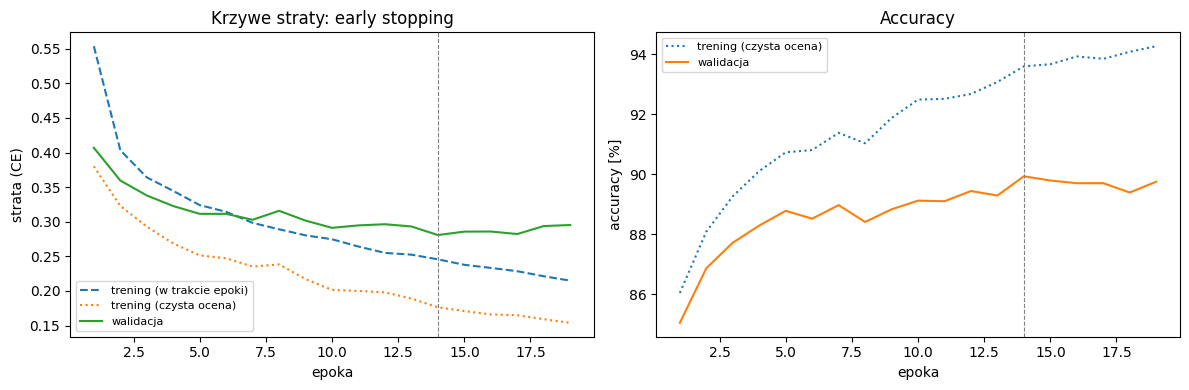

In [15]:
es_kwargs = dict(results[best_name]["kwargs"])
es_kwargs.update(epochs=60, patience=5, sched_step=EPOCHS // 3)
es_res = run_experiment(f"{best_name} + early stopping", **es_kwargs)
print(pd.DataFrame([summarize(es_res)]).T)
plot_curves(es_res, "early stopping")

## 4. Analiza i interpretacja

**Baseline.** Model bazowy ma najniższą stratę walidacyjną (0,304) w epoce 9, przy accuracy walidacyjnej 88,86% i accuracy treningowej (czysta ocena) 92,82%. Po tej epoce strata treningowa dalej maleje (do ok. 0,10 w epoce 20), a strata walidacyjna rośnie (do ok. 0,37), czyli model się przeucza. Accuracy walidacyjna w tym czasie nie spada (ok. 89–89,8%), bo model nadal trafia w podobną liczbę przypadków, ale staje się coraz pewniejszy także przy błędnych odpowiedziach, co podnosi entropię krzyżową. Wybór checkpointu po stracie walidacyjnej (zgodnie z zadaniem) wskazuje więc epokę 9, mimo że accuracy w późniejszych epokach bywa nieco wyższa.

**Pojedyncze ulepszenia.** BatchNorm (89,73%), weight decay 1e-4 (89,69%), scheduler StepLR (89,41%) i dropout 0,3 (89,30%) poprawiły accuracy walidacyjną o 0,4–0,9 p.p. względem baseline (88,86%). Najniższą stratę walidacyjną z pojedynczych ulepszeń dał scheduler (0,290), następnie dropout (0,300) i BatchNorm (0,302); weight decay (0,304) nie zmienił jej względem baseline. Różnice rzędu 0,5 p.p. są porównywalne z błędem standardowym accuracy na 10 000 próbek (ok. 0,3 p.p.) i pochodzą z jednego seeda, dlatego nie należy ich nadinterpretować. Warto zauważyć, że BatchNorm zwiększył lukę (0,166 wobec 0,114): sieć lepiej dopasowała trening (accuracy treningowa 95,10%), ale strata walidacyjna nie spadła. Dropout i scheduler luką zmniejszyły (0,097 i 0,092). Weight decay 1e-4 to słaba kara L2, więc jego wpływ jest niewielki. **Augmentacja pogorszyła wynik**: 85,26% (−3,6 p.p.) przy najlepszej epoce 19 (czyli przy końcu budżetu), z bardzo małą luką (0,022).

**Kombinacje.** Połączenie BatchNorm i dropout dało najlepszy wynik: strata walidacyjna 0,281 (epoka 14) i accuracy walidacyjna 89,93% (+1,07 p.p. względem baseline). Dodanie augmentacji do tej pary (aug + BN + dropout) lub wszystkich technik naraz („wszystko razem") obniżyło accuracy do 84,35% i 83,52%, a najlepsza epoka wypadła na końcu budżetu (19 i 20).

**Luka generalizacji.** Dla baseline luka `val_loss − train_eval_loss` wynosi 0,114 (epoka 9), dla wybranego modelu BN + dropout 0,104 (epoka 14), więc jest zbliżona (różnica 0,010), ale towarzyszy jej wyższa accuracy walidacyjna (89,93% vs 88,86%) oraz niższa strata walidacyjna (0,281 vs 0,304). Wybrany model nie jest więc „lepszy, bo mniej dopasowany": lepiej dopasowuje trening (accuracy treningowa 93,59% vs 92,82%) i jednocześnie lepiej generalizuje. Odwrotny przypadek to warianty z augmentacją: luka jest bardzo mała (0,013–0,022), ale accuracy walidacyjna jest najniższa (83,5–85,3%), a accuracy treningowa (czysta ocena) wynosi tylko 84–86%. To **niedouczenie**, a nie dobra generalizacja: model nie nauczył się nawet zbioru treningowego w zadanym budżecie 20 epok. Prawdopodobna przyczyna (hipoteza, nie testowana osobno) to zbyt silna augmentacja dla MLP: losowe przesunięcia do ±4 px sprawiają, że sieć bez struktury splotowej musi uczyć się każdego przesunięcia osobno, więc zbieżność jest wolniejsza.

**Wynik testowy (decyzja zamrożona).** Na zbiorze testowym baseline uzyskał 88,37% (strata 0,329), a wybrany model BN + dropout 89,52% (strata 0,300), czyli +1,15 p.p. Kolejność i różnica są zgodne z walidacją (88,86% → 89,93%); oba wyniki testowe są o ok. 0,4–0,5 p.p. niższe od walidacyjnych, co jest typowe, gdy wybór epoki i konfiguracji dokonywał się na walidacji.

**Zakres dodatkowy.** *Przegląd LR (baseline, 10 epok, walidacja):* najlepszy jest lr = 1e-3 (88,86%, strata 0,304). Przy 1e-2 wynik spada (86,47%), przy 1e-4 uczenie jest zbyt wolne (87,39%, najlepsza epoka to ostatnia, 10), a przy 1e-1 trening się rozbija: accuracy 10,27% (poziom losowy), a strata 2,304 odpowiada ln(10), czyli zgadywaniu. *Early stopping* (cierpliwość 5) zatrzymał trening po epoce 19 i przywrócił checkpoint z epoki 14 (89,93%, strata 0,281). Wynik jest identyczny jak w głównym eksperymencie, bo seed jest ten sam, a po epoce 14 strata walidacyjna już się nie poprawiała. Zysk to oszczędność epok (w tym eksperymencie 1 z 20, przy dłuższym budżecie więcej) i brak ryzyka wyboru złego momentu.

**Ograniczenia.** Jeden seed i jeden podział walidacyjny, więc różnice poniżej ok. 0,5 p.p. nie są wiarygodne. Siła regularyzacji (p dropoutu, weight decay, zakres augmentacji) nie była strojona, a augmentację przetestowano tylko w jednym, dość silnym ustawieniu. Budżet 20 epok jest za krótki dla wariantów z augmentacją. Konfigurację wybrano spośród 9 kandydatów na tym samym zbiorze walidacyjnym, co daje lekki optymizm walidacji, i właśnie dlatego ostateczną ocenę wykonano na osobnym zbiorze testowym. MLP nie wykorzystuje struktury przestrzennej obrazu.

## 5. Wnioski
1. **Baseline** (MLP 256-128, Adam 1e-3): val accuracy 88,86% w epoce 9 (najniższa strata walidacyjna 0,304), luka generalizacji 0,114. Po epoce 9 model się przeucza (strata walidacyjna rośnie przy malejącej stracie treningowej).
2. **Najlepsza konfiguracja** wg straty walidacyjnej: **BatchNorm + dropout 0,3**, epoka 14: val loss 0,281, val accuracy 89,93% (+1,07 p.p.), luka 0,104.
3. **Pojedyncze ulepszenia:** BatchNorm, weight decay, scheduler i dropout dały +0,4–0,9 p.p. accuracy walidacyjnej (porównywalne z szumem jednego seeda); dropout i scheduler zmniejszyły lukę, BatchNorm ją zwiększył. **Augmentacja pogorszyła wynik** (85,26%) i wraz z kombinacjami z nią (83,5–84,4%) wykazuje niedouczenie: mała luka (0,013–0,022) przy niskiej accuracy.
4. **Końcowa accuracy testowa:** baseline **88,37%**, wybrany model **89,52%** (+1,15 p.p.), zgodnie z kierunkiem z walidacji.
5. **Zakres dodatkowy:** najlepszy lr = 1e-3 (lr = 1e-1 rozbija trening do poziomu losowego); early stopping (cierpliwość 5) zatrzymał trening po epoce 19 i przywrócił najlepszy checkpoint z epoki 14.
6. **Kierunki poprawy:** słabsza augmentacja (mniejszy padding) i dłuższy budżet epok, strojenie p dropoutu i weight decay, kilka seedów i uśrednianie, sieci splotowe (CNN).